# Predicting Swing-and-Miss in Major League Baseball

## Research Question
Which pitch characteristics are most predictive of a swing-and-miss in MLB?

## Introduction
Whiffs are an important component of pitcher effectiveness because there are many situations in which generating a swing-and-miss can help a pitcher record a strikeout or avoid contact. Understanding which pitch characteristics are associated with whiffs can therefore provide useful information for pitchers, catchers, coaches, and analysts. This project examines which pitch characteristics are most predictive of a swing-and-miss using MLB Statcast pitch-level data. Data from April 1-7, 2024 are used for model development, while data from April 15-21, 2024 are reserved for external validation. The modeling process begins with pitch velocity and progressively adds movement, location, contextual information, and an engineered strike-zone-relative location feature to evaluate how each group of variables contributes to predictive performance.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
!pip install pybaseball

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.6/455.6 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.9 MB/s eta 0:00:00


In [9]:
from pybaseball import statcast

## Data Collection
Pitch-level Statcast data was collected using the pybaseball package. Each row represents an individual MLB pitch.

In [10]:
project_data= statcast("2024-04-01","2024-04-07")

This is a large query, it may take a moment to complete


  0%|          | 0/7 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
 14%|█▍        | 1/7 [00:04<00:29,  4.87s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exception

In [11]:
project_data.shape

(26073, 119)

In [12]:
project_data.head()

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
2651,CU,2024-04-07,85.2,-2.31,6.16,"Johnson, Pierce",664983,572955,field_out,hit_into_play,...,2,3.78,-0.73,0.73,36.0,21.26133,-9.620944,34.858224,44.484484,39.961796
2674,CU,2024-04-07,86.0,-2.33,6.15,"Johnson, Pierce",664983,572955,NaN,called_strike,...,2,3.52,-0.78,0.78,41.6,<NA>,<NA>,<NA>,<NA>,<NA>
2819,CU,2024-04-07,85.8,-2.27,6.2,"Johnson, Pierce",553993,572955,field_out,hit_into_play,...,1,3.49,-0.91,-0.91,42.2,14.211988,7.795369,34.318302,45.151528,27.733033
2909,CU,2024-04-07,86.5,-2.3,6.24,"Johnson, Pierce",572233,572955,single,hit_into_play,...,1,3.39,-0.9,-0.9,38.3,4.061736,9.400294,24.872673,33.739691,28.735222
2988,CU,2024-04-07,86.1,-2.18,6.16,"Johnson, Pierce",572233,572955,NaN,ball,...,1,3.51,-1.14,-1.14,40.2,<NA>,<NA>,<NA>,<NA>,<NA>


In [13]:
project_data["description"].value_counts()

,count
description,
ball,8723
foul,4556
hit_into_play,4452
called_strike,4410
swinging_strike,2644
blocked_ball,634
foul_tip,295
swinging_strike_blocked,135
hit_by_pitch,83


## Target Definition

The analysis is restricted to pitches on which the batter swung. The target variable identifies whether a swing resulted in a whiff or contact.

**Whiff (1):**
- Swinging strike
- Blocked swinging strike

**Contact (0):**
- Foul ball
- Ball put into play
- Foul tip

Bunt attempts are excluded because bunting represents a different type of hitting action from a conventional swing.

In [14]:
whiff_events=[
    "swinging_strike",
    "swinging_strike_blocked"
]
contact_events=[
    "foul",
    "hit_into_play",
    "foul_tip"
]

In [15]:
swing_events=whiff_events + contact_events

In [16]:
swings=project_data[
    project_data["description"].isin(swing_events)
].copy()



In [17]:
swings.shape

(12082, 119)

In [18]:
swings["description"].value_counts()

,count
description,
foul,4556
hit_into_play,4452
swinging_strike,2644
foul_tip,295
swinging_strike_blocked,135


In [19]:
swings["whiff"]=swings["description"].isin(whiff_events).astype(int)

In [20]:
swings["whiff"].value_counts()

,count
whiff,
0,9303
1,2779


In [21]:
swings["whiff"].mean()

np.float64(0.23001158748551565)

In [22]:
potential_features=[
    "release_speed",
    "pfx_x",
    "pfx_z",
    "plate_x",
    "plate_z",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes"
]


In [23]:
swings[potential_features].head(10)

,release_speed,pfx_x,pfx_z,plate_x,plate_z,pitch_type,stand,p_throws,balls,strikes
2651,85.2,0.73,-0.65,-0.279656,1.838491,CU,L,R,0,1
2819,85.8,0.91,-0.38,1.05556,2.308806,CU,R,R,0,0
2909,86.5,0.9,-0.36,-0.355228,2.686424,CU,R,R,2,2
3092,85.7,0.78,-0.46,-0.450543,2.966066,CU,R,R,1,1
3161,84.9,0.83,-0.4,0.983339,2.064041,CU,R,R,1,0
3389,84.3,1.16,-0.46,-0.204086,2.866817,CU,R,R,2,2
3549,84.5,1.16,-0.25,0.431463,2.780942,CU,R,R,1,2
3761,84.4,1.25,-0.28,1.371602,1.594108,CU,R,R,0,2
3884,84.1,1.15,-0.35,-0.022921,3.574306,CU,R,R,0,1
2128,82.4,1.27,0.21,0.628752,2.688721,SL,R,R,1,2


In [24]:
swings[potential_features].isna().sum()

,0
release_speed,1
pfx_x,1
pfx_z,1
plate_x,1
plate_z,1
pitch_type,1
stand,0
p_throws,0
balls,0
strikes,0


In [25]:
swings[potential_features].dtypes

,0
release_speed,Float64
pfx_x,Float64
pfx_z,Float64
plate_x,Float64
plate_z,Float64
pitch_type,object
stand,object
p_throws,object
balls,Int64
strikes,Int64


In [26]:
model_data=swings.dropna(subset=potential_features).copy()

In [27]:
model_data.shape

(12081, 120)

## Data Cleaning

Potential predictor variables were checked for missing values. One of 12,082 swings contained missing pitch-tracking information. Because this represented a negligible portion of the sample, the observation was removed rather than imputed.

In [28]:
model_data.groupby("pitch_type")["whiff"].agg(["count","mean"]).sort_values("count",ascending=False)

,count,mean
pitch_type,,
FF,3806,0.189963
SL,1896,0.316983
SI,1865,0.131903
CH,1332,0.280781
FC,1013,0.196446
ST,899,0.275862
CU,591,0.274112
FS,447,0.362416
KC,150,0.293333


In [29]:
four_seamers=model_data[
    model_data["pitch_type"]=="FF"
].copy()

In [30]:
four_seamers.groupby("whiff")["release_speed"].mean().round(1)

,release_speed
whiff,
0,93.9
1,94.3


In [31]:
common_pitches = ["FF", "SL", "SI", "CH", "FC"]


In [32]:
velocity_by_pitch=(
    model_data[model_data["pitch_type"].isin(common_pitches)]
    .groupby(["pitch_type","whiff"])["release_speed"]
    .mean()
    .round(1)
)

In [33]:
velocity_by_pitch

pitch_type  whiff
CH          0        85.1
            1        84.8
FC          0        89.3
            1        89.4
FF          0        93.9
            1        94.3
SI          0        92.9
            1        92.9
SL          0        85.5
            1        85.6
Name: release_speed, dtype: Float64

In [34]:
sliders=model_data[
    model_data["pitch_type"]=="SL"
].copy()

In [35]:
sliders.groupby("whiff")[["pfx_x","pfx_z"]].mean().round(2)

,pfx_x,pfx_z
whiff,,
0,0.2,0.17
1,0.2,0.15


In [36]:
sliders["p_throws"].value_counts()

,count
p_throws,
R,1507
L,389


In [37]:
righty_sliders = sliders[
    sliders["p_throws"] == "R"
].copy()

In [38]:
righty_sliders.groupby("whiff")[["pfx_x", "pfx_z"]].mean().round(2)

,pfx_x,pfx_z
whiff,,
0,0.35,0.19
1,0.34,0.17


In [39]:
slider_contact = sliders[sliders["whiff"] == 0]
slider_whiffs = sliders[sliders["whiff"] == 1]

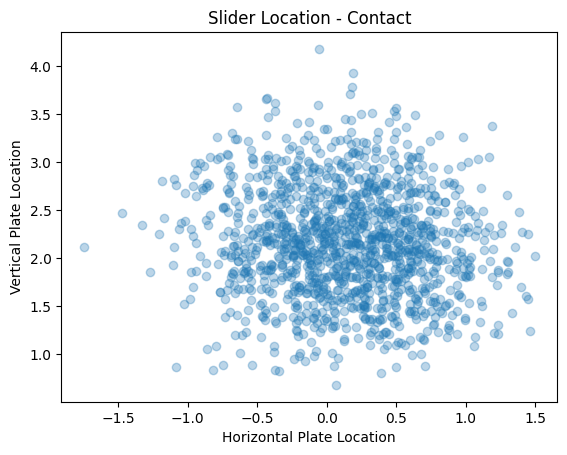

In [40]:
plt.scatter(
    slider_contact["plate_x"],
    slider_contact["plate_z"],
    alpha=0.3
)

plt.xlabel("Horizontal Plate Location")
plt.ylabel("Vertical Plate Location")
plt.title("Slider Location - Contact")

plt.show()

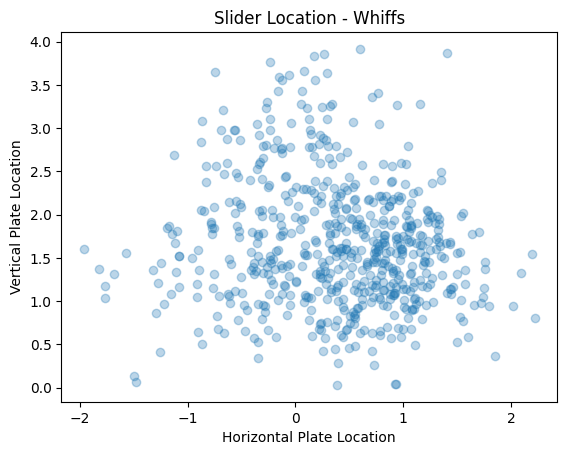

In [41]:
plt.scatter(
    slider_whiffs["plate_x"],
    slider_whiffs["plate_z"],
    alpha=0.3
)

plt.xlabel("Horizontal Plate Location")
plt.ylabel("Vertical Plate Location")
plt.title("Slider Location - Whiffs")

plt.show()

In [42]:
sliders.groupby("whiff")["plate_z"].mean().round(2)

,plate_z
whiff,
0,2.16
1,1.67


In [43]:
sliders.groupby("whiff")["plate_z"].median().round(2)

,plate_z
whiff,
0,2.15
1,1.58


In [44]:
low_sliders = sliders[sliders["plate_z"] < 2.0]

In [45]:
low_sliders["whiff"].mean()

np.float64(0.4609704641350211)

In [46]:
high_sliders = sliders[sliders["plate_z"] >= 2.0]

In [47]:
high_sliders["whiff"].mean()

np.float64(0.1729957805907173)

In [48]:
righty_batter_sliders = sliders[
    sliders["stand"] == "R"
].copy()

In [49]:
len(righty_batter_sliders)

1215

In [50]:
righty_batter_sliders.groupby("whiff")["plate_x"].mean().round(2)

,plate_x
whiff,
0,0.16
1,0.47


In [51]:
righty_batter_sliders.groupby("whiff")["plate_x"].median().round(2)

,plate_x
whiff,
0,0.21
1,0.55


In [52]:
righty_contact = righty_batter_sliders[
    righty_batter_sliders["whiff"] == 0
]

righty_whiffs = righty_batter_sliders[
    righty_batter_sliders["whiff"] == 1
]

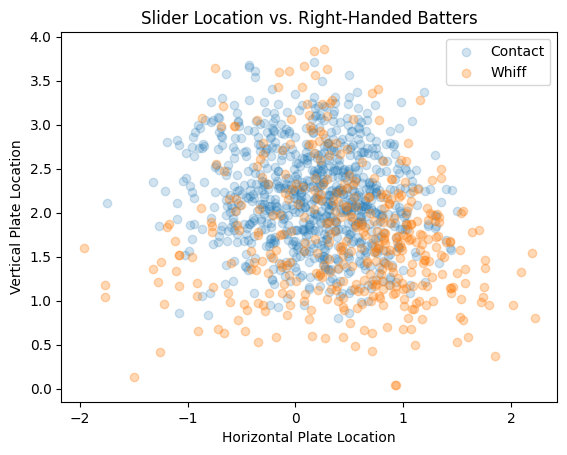

In [53]:
plt.scatter(
    righty_contact["plate_x"],
    righty_contact["plate_z"],
    alpha=0.2,
    label="Contact"
)
plt.scatter(
    righty_whiffs["plate_x"],
    righty_whiffs["plate_z"],
    alpha=0.3,
    label="Whiff"
)

plt.xlabel("Horizontal Plate Location")
plt.ylabel("Vertical Plate Location")
plt.title("Slider Location vs. Right-Handed Batters")
plt.legend()

plt.show()

In [54]:
outside_sliders = righty_batter_sliders[
    righty_batter_sliders["plate_x"] > 0.5
]

not_outside_sliders = righty_batter_sliders[
    righty_batter_sliders["plate_x"] <= 0.5
]

In [55]:
outside_sliders["whiff"].mean()

np.float64(0.47058823529411764)

In [56]:
not_outside_sliders["whiff"].mean()

np.float64(0.2445019404915912)

In [57]:
low_outside_sliders = righty_batter_sliders[
    (righty_batter_sliders["plate_z"] < 2.0) &
    (righty_batter_sliders["plate_x"] > 0.5)
]

In [58]:
len(low_outside_sliders)

270

In [59]:
low_outside_sliders["whiff"].mean()


np.float64(0.6259259259259259)

## Exploratory Analysis Findings

**Velocity:**
Velocity showed relatively small differences between whiffs and contact. Across the most common pitch types, pitches resulting in whiffs generally had similar average velocities to pitches resulting in contact. For example, four-seam fastballs resulting in contact averaged 93.9 mph compared with 94.3 mph on whiffs. This suggests that velocity alone may have limited ability to distinguish whiffs from contact.

**Movement:**
Movement also showed relatively small differences. For sliders, swings resulting in whiffs had similar average movement to those resulting in contact.

**Location:**
Location showed much larger differences.Sliders below two feet produced a 46% whiff rate compared with 17% for sliders at or above two feet. Against right-handed hitters, sliders classified as outside produced a 47% whiff rate compared with 24% for other locations. Sliders that were low and away produced a significantly higher whiff rate of 63%.

**Initial Hypothesis:**
Based on exploratory analysis, location may provide more predictive information on a pitch's whiff potential than velocity or movement. However, this could be more important for sliders and other breaking balls or offspeed pitches than it is for fastballs. Different factors could provide more or less information for different pitch tpyes.

## Predictive Modeling

Models were developed incrementally to evaluate how different categories of pitch characteristics contribute to predicting swing-and-miss outcomes.

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

In [61]:
X_velocity=model_data[["release_speed"]]
y=model_data["whiff"]

In [62]:
rf_velocity=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [63]:
velocity_scores = cross_val_score(
    rf_velocity,
    X_velocity,
    y,
    cv=5,
    scoring="roc_auc"
)


In [64]:
print(velocity_scores)

[0.54519694 0.55424576 0.56013866 0.58102373 0.54452067]


In [65]:
print("average AUC:",round(velocity_scores.mean(),3))

average AUC: 0.557


In [66]:
X_movement = model_data[
    ["release_speed", "pfx_x", "pfx_z"]
]

In [67]:
rf_movement = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [68]:
movement_scores = cross_val_score(
    rf_movement,
    X_movement,
    y,
    cv=5,
    scoring="roc_auc"
)

print(movement_scores)
print("Average AUC:", round(movement_scores.mean(), 3))

[0.5317145  0.55384977 0.56149629 0.55388431 0.53779493]
Average AUC: 0.548


In [69]:
X_location = model_data[
    [
        "release_speed",
        "pfx_x",
        "pfx_z",
        "plate_x",
        "plate_z"
    ]
]

In [70]:
rf_location = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [71]:
location_scores = cross_val_score(
    rf_location,
    X_location,
    y,
    cv=5,
    scoring="roc_auc"
)

In [72]:
print(location_scores)
print("Average AUC:",round(location_scores.mean(),3))

[0.67970245 0.70732581 0.7222364  0.72860099 0.72119933]
Average AUC: 0.712


In [73]:
full_features = [
    "release_speed",
    "pfx_x",
    "pfx_z",
    "plate_x",
    "plate_z",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes"
]

X_full = model_data[full_features].copy()

In [74]:
categorical_features = [
    "pitch_type",
    "stand",
    "p_throws"
]

In [75]:
X_full = pd.get_dummies(
    X_full,
    columns=categorical_features,
    drop_first=True
)

In [76]:
X_full.shape

(12081, 23)

In [77]:
X_full.head()

,release_speed,pfx_x,pfx_z,plate_x,plate_z,balls,strikes,pitch_type_CS,pitch_type_CU,pitch_type_EP,...,pitch_type_FO,pitch_type_FS,pitch_type_KC,pitch_type_KN,pitch_type_SI,pitch_type_SL,pitch_type_ST,pitch_type_SV,stand_R,p_throws_R
2651,85.2,0.73,-0.65,-0.279656,1.838491,0,1,False,True,False,...,False,False,False,False,False,False,False,False,False,True
2819,85.8,0.91,-0.38,1.05556,2.308806,0,0,False,True,False,...,False,False,False,False,False,False,False,False,True,True
2909,86.5,0.9,-0.36,-0.355228,2.686424,2,2,False,True,False,...,False,False,False,False,False,False,False,False,True,True
3092,85.7,0.78,-0.46,-0.450543,2.966066,1,1,False,True,False,...,False,False,False,False,False,False,False,False,True,True
3161,84.9,0.83,-0.4,0.983339,2.064041,1,0,False,True,False,...,False,False,False,False,False,False,False,False,True,True


In [78]:
X_full.columns.tolist()

['release_speed',
 'pfx_x',
 'pfx_z',
 'plate_x',
 'plate_z',
 'balls',
 'strikes',
 'pitch_type_CS',
 'pitch_type_CU',
 'pitch_type_EP',
 'pitch_type_FA',
 'pitch_type_FC',
 'pitch_type_FF',
 'pitch_type_FO',
 'pitch_type_FS',
 'pitch_type_KC',
 'pitch_type_KN',
 'pitch_type_SI',
 'pitch_type_SL',
 'pitch_type_ST',
 'pitch_type_SV',
 'stand_R',
 'p_throws_R']

In [79]:
rf_full = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

full_scores = cross_val_score(
    rf_full,
    X_full,
    y,
    cv=5,
    scoring="roc_auc"
)

print(full_scores)
print("Average AUC:", round(full_scores.mean(), 3))

[0.70243816 0.71416414 0.75124014 0.73683666 0.73221745]
Average AUC: 0.727


In [80]:
rf_full.fit(X_full, y)

RandomForestClassifier(random_state=42)

In [81]:
feature_importance = pd.DataFrame({
    "Feature": X_full.columns,
    "Importance": rf_full.feature_importances_
})

In [82]:
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,plate_z,0.266392
3,plate_x,0.176578
0,release_speed,0.140352
2,pfx_z,0.140049
1,pfx_x,0.139097
5,balls,0.036150
6,strikes,0.033913
21,stand_R,0.018854
22,p_throws_R,0.011313
18,pitch_type_SL,0.006693


In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_full,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [84]:
print("Training:", len(X_train))
print("Testing:", len(X_test))

print("Training whiff rate:", round(y_train.mean(), 3))
print("Testing whiff rate:", round(y_test.mean(), 3))

Training: 9664
Testing: 2417
Training whiff rate: 0.23
Testing whiff rate: 0.23


In [85]:
rf_test = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_test.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [86]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_test,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42
)

In [87]:
perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
})

perm_importance = perm_importance.sort_values(
    "Importance",
    ascending=False
)

perm_importance.head(10)

,Feature,Importance
4,plate_z,0.135772
3,plate_x,0.028847
1,pfx_x,0.015985
0,release_speed,0.014525
17,pitch_type_SI,0.011808
2,pfx_z,0.011202
21,stand_R,0.008559
6,strikes,0.008348
14,pitch_type_FS,0.004205
22,p_throws_R,0.004160


In [88]:
model_data[["sz_bot", "sz_top"]].isna().sum()

,0
sz_bot,0
sz_top,0


In [89]:
model_data[["plate_z", "sz_bot", "sz_top"]].head(10)

,plate_z,sz_bot,sz_top
2651,1.838491,1.68,3.45
2819,2.308806,1.61,3.46
2909,2.686424,1.53,3.41
3092,2.966066,1.53,3.41
3161,2.064041,1.53,3.41
3389,2.866817,1.7,3.62
3549,2.780942,1.7,3.62
3761,1.594108,1.7,3.62
3884,3.574306,1.7,3.62
2128,2.688721,1.74,3.51


## Feauture Engineering
Exploratory analysis suggested that vertical pitch location was strongly associated with swing-and-miss outcomes. However, plate_z measures pitch height in absolute feet and does not account for differences in batter strike-zone height. To represent vertical location relative to each batter's estimated strike zone, I created a relative_plate_z feature using Statcast's sz_bot and sz_top measurements.
A value of 0 represents the estimated bottom of the batter's strike zone, 1 represents the top of the zone, values below 0 represent pitches below the zone, and values above 1 represent pitches above the zone. This feature was evaluated alongside absolute vertical location to determine whether batter-relative location provided additional predictive information.

In [90]:
model_data["zone_height"] = (
    model_data["sz_top"] - model_data["sz_bot"]
)

model_data["relative_plate_z"] = (
    (model_data["plate_z"] - model_data["sz_bot"])
    / model_data["zone_height"]
)

In [91]:
model_data[
    ["plate_z", "sz_bot", "sz_top", "relative_plate_z"]
].head(10)

,plate_z,sz_bot,sz_top,relative_plate_z
2651,1.838491,1.68,3.45,0.089543
2819,2.308806,1.61,3.46,0.377733
2909,2.686424,1.53,3.41,0.615119
3092,2.966066,1.53,3.41,0.763865
3161,2.064041,1.53,3.41,0.284065
3389,2.866817,1.7,3.62,0.607717
3549,2.780942,1.7,3.62,0.56299
3761,1.594108,1.7,3.62,-0.055152
3884,3.574306,1.7,3.62,0.976201
2128,2.688721,1.74,3.51,0.536001


In [92]:
below_zone_sliders = sliders[
    sliders["plate_z"] < sliders["sz_bot"]
]

In [93]:
in_or_above_sliders = sliders[
    sliders["plate_z"] >= sliders["sz_bot"]
]

In [94]:
below_zone_sliders["whiff"].mean()

np.float64(0.5770676691729323)

In [95]:
in_or_above_sliders["whiff"].mean()

np.float64(0.2155425219941349)

In [96]:
len(below_zone_sliders)

532

In [97]:
relative_features = [
    "release_speed",
    "pfx_x",
    "pfx_z",
    "plate_x",
    "relative_plate_z",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes"
]

X_relative = model_data[relative_features].copy()

In [98]:
X_relative = pd.get_dummies(
    X_relative,
    columns=["pitch_type", "stand", "p_throws"],
    drop_first=True
)

In [99]:
X_relative.isna().sum().sum()

np.int64(0)

In [100]:
rf_relative = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

relative_scores = cross_val_score(
    rf_relative,
    X_relative,
    y,
    cv=5,
    scoring="roc_auc"
)

print(relative_scores)
print("Average AUC:", round(relative_scores.mean(), 3))

[0.70240143 0.71110224 0.76079427 0.73652046 0.72329765]
Average AUC: 0.727


In [101]:
engineered_features = [
    "release_speed",
    "pfx_x",
    "pfx_z",
    "plate_x",
    "plate_z",
    "relative_plate_z",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes"
]

X_engineered = model_data[engineered_features].copy()

X_engineered = pd.get_dummies(
    X_engineered,
    columns=["pitch_type", "stand", "p_throws"],
    drop_first=True
)

In [102]:
rf_engineered = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

engineered_scores = cross_val_score(
    rf_engineered,
    X_engineered,
    y,
    cv=5,
    scoring="roc_auc"
)

print(engineered_scores)
print("Average AUC:", round(engineered_scores.mean(), 3))

[0.71372531 0.72115834 0.75368802 0.74291115 0.74508973]
Average AUC: 0.735


Replacing absolute vertical location with the relative measure did not improve cross-validated ROC-AUC, but including both features increased ROC-AUC from 0.727 to 0.735. Therefore, the final model retained both absolute and batter-relative vertical location.

## Final Model Selection
The final Random Forest model includes velocity, horizontal and vertical movement, horizontal and vertical pitch location, batter-relative vertical location, pitch type, batter and pitcher handedness, and count. This feature set produced the highest cross-validated ROC-AUC of 0.735 during model development. The model specification was then frozen before evaluation on the separate external validation period.

## External Validation

After model development using April 1–7, 2024 data, the final feature specification was frozen and evaluated on a separate period of MLB games. This provides a stronger test of whether the relationships identified during model development generalize to unseen data.

In [103]:
validation_data = statcast("2024-04-15", "2024-04-21")

This is a large query, it may take a moment to complete


  0%|          | 0/7 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
 14%|█▍        | 1/7 [00:02<00:13,  2.30s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
 29%|██▊       | 2/7 [00:08<00:22,  4.41s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime

In [104]:
validation_data.shape

(27986, 119)

In [105]:
whiff_events = [
    "swinging_strike",
    "swinging_strike_blocked"
]

contact_events = [
    "foul",
    "hit_into_play",
    "foul_tip"
]

swing_events = whiff_events + contact_events

In [106]:
validation_swings = validation_data[
    validation_data["description"].isin(swing_events)
].copy()

In [107]:
validation_swings["whiff"] = (
    validation_swings["description"]
    .isin(whiff_events)
    .astype(int)
)

In [108]:
print("Swings:", len(validation_swings))
print("Whiff rate:", round(validation_swings["whiff"].mean(), 3))

Swings: 12998
Whiff rate: 0.226


In [109]:
validation_swings["zone_height"] = (
    validation_swings["sz_top"] -
    validation_swings["sz_bot"]
)

validation_swings["relative_plate_z"] = (
    (validation_swings["plate_z"] - validation_swings["sz_bot"])
    / validation_swings["zone_height"]
)

In [110]:
validation_features = [
    "release_speed",
    "pfx_x",
    "pfx_z",
    "plate_x",
    "plate_z",
    "relative_plate_z",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes"
]

validation_model_data = validation_swings.dropna(
    subset=validation_features
).copy()

In [111]:
X_validation = validation_model_data[
    validation_features
].copy()

X_validation = pd.get_dummies(
    X_validation,
    columns=["pitch_type", "stand", "p_throws"],
    drop_first=True
)

In [112]:
X_validation = X_validation.reindex(
    columns=X_engineered.columns,
    fill_value=0
)

In [113]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X_engineered, y)

RandomForestClassifier(random_state=42)

In [114]:
y_validation = validation_model_data["whiff"]

validation_probabilities = final_model.predict_proba(
    X_validation
)[:, 1]

In [115]:
from sklearn.metrics import roc_auc_score

In [116]:
validation_auc = roc_auc_score(
    y_validation,
    validation_probabilities
)

print("External Validation AUC:", round(validation_auc, 3))

External Validation AUC: 0.742


In [117]:
model_results = pd.DataFrame({
    "Model": [
        "Velocity",
        "+ Movement",
        "+ Location",
        "+ Context",
        "+ Relative Location"
    ],
    "AUC": [
        0.557,
        0.548,
        0.712,
        0.727,
        0.735
    ]
})

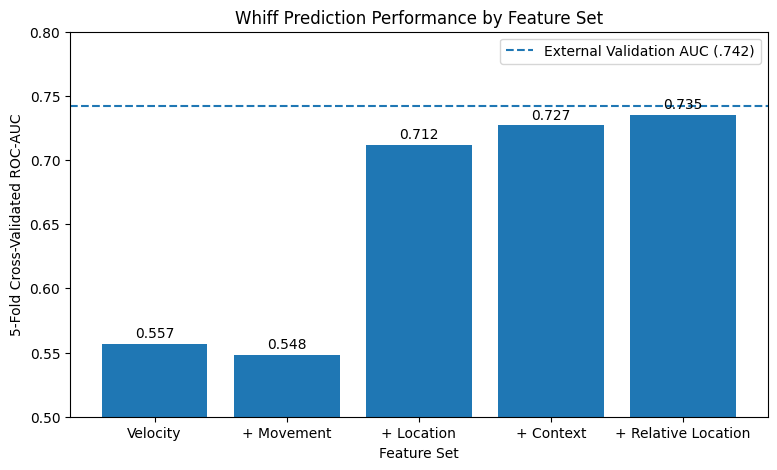

In [118]:
plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["AUC"]
)

plt.ylabel("5-Fold Cross-Validated ROC-AUC")
plt.xlabel("Feature Set")
plt.title("Whiff Prediction Performance by Feature Set")

plt.ylim(0.5, 0.8)
plt.axhline(
    y=0.742,
    linestyle="--",
    label="External Validation AUC (.742)"
)

plt.legend()
for index, value in enumerate(model_results["AUC"]):
    plt.text(
        index,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.show()

In [119]:
slider_location_results = pd.DataFrame({
    "Location": [
        "Below Zone",
        "At/Above Zone Bottom"
    ],
    "Whiff Rate": [
        0.577,
        0.212
    ]
})

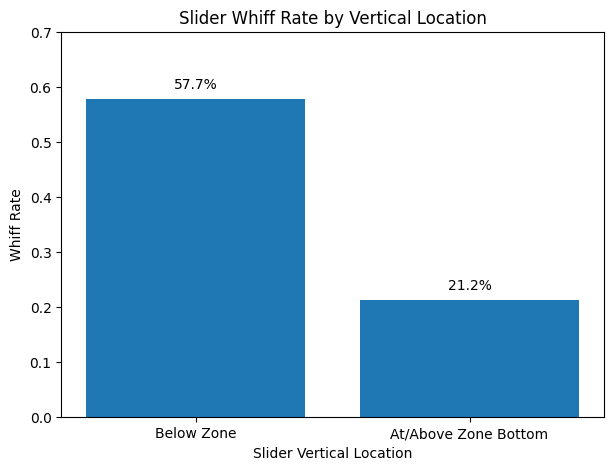

In [120]:
plt.figure(figsize=(7, 5))

plt.bar(
    slider_location_results["Location"],
    slider_location_results["Whiff Rate"]
)

plt.ylabel("Whiff Rate")
plt.xlabel("Slider Vertical Location")
plt.title("Slider Whiff Rate by Vertical Location")

plt.ylim(0, 0.7)
for index, value in enumerate(slider_location_results["Whiff Rate"]):
    plt.text(
        index,
        value + 0.02,
        f"{value:.1%}",
        ha="center"
    )

plt.show()

Sliders below the batter-specific bottom of the strike zone generated a 57.7% whiff rate, compared with 21.2% for sliders at or above the bottom of the zone. This descriptive result supports the broader modeling finding that vertical pitch location contains substantial information for predicting swing-and-miss outcomes.

In [121]:
top_perm = perm_importance.head(10).sort_values(
    "Importance",
    ascending=True
)

In [122]:
feature_names = {
    "plate_z": "Vertical Location",
    "plate_x": "Horizontal Location",
    "pfx_x": "Horizontal Movement",
    "pfx_z": "Vertical Movement",
    "release_speed": "Velocity",
    "pitch_type_SI": "Sinker",
    "stand_R": "Right-Handed Batter",
    "strikes": "Strikes in Count",
    "pitch_type_FS": "Splitter",
    "p_throws_R": "Right-Handed Pitcher"
}

top_perm["Feature"] = (
    top_perm["Feature"]
    .replace(feature_names)
)

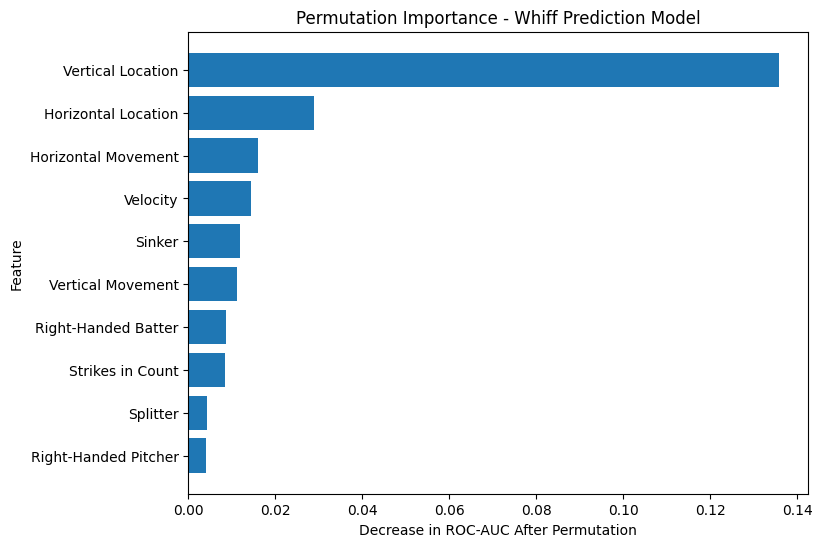

In [123]:
plt.figure(figsize=(8, 6))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance"]
)

plt.xlabel("Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")
plt.title("Permutation Importance - Whiff Prediction Model")

plt.show()

## Results
### Model Performance
Velocity alone had limited predictive ability, producing a cross-validated ROC-AUC of 0.557. Adding movement did not improve model performance, while adding pitch location increased ROC-AUC substantially to 0.712. Additional context and the engineered relative vertical-location feature produced smaller improvements, resulting in a final cross-validated ROC-AUC of 0.735. The frozen final model achieved an ROC-AUC of 0.742 on a completely separate validation week, suggesting that its predictive performance generalized to unseen data.
### Feature Importance
Permuting vertical location produced a 0.136 decrease in ROC-AUC, the largest decrease among the features tested. Horizontal location, horizontal movement, and velocity produced smaller decreases of 0.029, 0.016, and 0.015, respectively. This indicates that vertical location provided the most important predictive information to the final model among the features evaluated.
### Baseball Interpretation
Sliders below the batter-specific bottom of the strike zone produced a 57.7% whiff rate, compared with 21.2% for sliders at or above the bottom of the zone. This descriptive result is consistent with the modeling results, which identified pitch location—particularly vertical location—as an important source of predictive information. For sliders specifically, the results suggest that pitches finishing below the strike zone were substantially more likely to generate a swing-and-miss in this sample.

## Limitations
I developed the model using data from only April 1-7, 2024. Although it performed well on a separate validation period from April 15-21, two weeks of baseball do not necessarily represent an entire MLB season. The time of the season could influence the results and lead to differences in pitcher characteristics or whiff rates. In addition, I only modeled the features included in this analysis. Other variables, such as pitch sequencing, pitcher and batter quality, previous pitches in the plate appearance, and game situation, may contain additional predictive information. The results demonstrate predictive relationships rather than causation; for example, they do not establish that simply throwing a slider lower will necessarily cause an increase in whiff probability. Finally, although Random Forest models can capture nonlinear relationships and interactions, they are less directly interpretable than simpler statistical models. Permutation importance indicates which features the model relies on for prediction, but it does not establish causal effects.

## Conclusion
This project examined which pitch characteristics are most predictive of a swing-and-miss in Major League Baseball. Model performance improved most substantially when pitch location was added, with cross-validated ROC-AUC increasing from 0.548 to 0.712. The final model achieved a cross-validated ROC-AUC of 0.735 and an ROC-AUC of 0.742 on a completely separate validation period. The baseball-specific analysis supported this result: sliders below the batter-specific strike zone produced a 57.7% whiff rate, more than 35 percentage points higher than sliders at or above the bottom of the zone. Overall, among the variables evaluated in this analysis, pitch location—particularly vertical location—provided the strongest predictive information for distinguishing whiffs from contact.